Business Understanding
context: Customer churn is a significant business concern for telecommunications companies because losing existing customers can reduce recurring revenue and increase the cost associated with acquiring replacement customers. Therefore, understanding which customers are likely to churn can enable a telecommunications company to take proactive retention actions.

Problem Statement: How can a telecommunications company use customer data and AI to identify customers who are at greater risk of churning, understand the factors associated with churn, and support proactive customer-retention decisions?

About Data: This sample data module tracks a fictional telco company's customer churn based on various factors. T he churn column indicates whether the customer departed within the last month. Other columns include gender, dependents, monthly charges, and many with information about the types of services each customer has.

Objectives:
To analyse historical patterns of customer churn
To develop an AI/ML model capable of predicting the likelihood of customer churn
To segment customers according to their level of churn risk
To identify customer characteristics and behaviours associated with churn
Relevant Source(s):

telco-customer-churn-on-icp4d
About Telco customer churn
Desk-based Research

Load Libraries

In [1]:
# !pip install xgboost

In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_score, recall_score, f1_score, accuracy_score)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

In [3]:
# constants: 
SEED_VALUE = 42
tf.keras.utils.set_random_seed(SEED_VALUE)   # makes results repeatable 


Load data

In [4]:
df = pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/refs/heads/master/data/Telco-Customer-Churn.csv")

Data Understanding & Preparation

In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [7]:
df.shape

(7043, 21)

Univariate Analysis

In [8]:
df_2 = df.drop(columns=["customerID"])

In [9]:

df_2.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [10]:
df.customerID.nunique()

7043

In [11]:
df_2.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [12]:
df_2.SeniorCitizen.value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

In [13]:
df_2[df_2["tenure"] == 0].head(2) # possible new customers

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No


In [14]:
tenures = df_2["tenure"].unique()
tenures.sort()
tenures

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
       68, 69, 70, 71, 72])

In [15]:
df_2.MonthlyCharges.describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

Customer size is 7043
SeniorCitizen:

Binary in nature, 0 representsot seniorcitizen while 1 represents senior citizen
5901 are not Senior citizrns but 1142 are Senior Citizens
tenure:

One average the customers ppurchased producin a duration ff 32.37 months
the variation between each customer duration was appprooximately 24 months
75% of the customers fell below 55% in terms of their purchase durations
50% of the customer population fell below 29 months
25% of the customer population fell below 9 months
the time period rangers from 0 - 72 with a center point of 20
MonthlyCharges:

Avg mnthly charge is 64.76
The highest bill is at 118
75% of the bills fall below 89.5
50% of the bills fall below 70.35
25% of the bills are below 35.5
the bills range between 18 - 118 in terms of cost

In [16]:
df_2.describe(include="object")

C:\Users\user\AppData\Local\Temp\ipykernel_20916\186925522.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_2.describe(include="object")


,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [17]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [18]:
df_2.Contract.unique()

<StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

In [19]:
no_churn_df = df_2[df_2["Churn"] == "No"]
no_churn_df["Contract"].value_counts()

Contract
Month-to-month    2220
Two year          1647
One year          1307
Name: count, dtype: int64

In [20]:
no_churn_df["StreamingMovies"].value_counts()

StreamingMovies
Yes                    1914
No                     1847
No internet service    1413
Name: count, dtype: int64

In [21]:
no_churn_df["PaymentMethod"].value_counts()

PaymentMethod
Mailed check                 1304
Electronic check             1294
Credit card (automatic)      1290
Bank transfer (automatic)    1286
Name: count, dtype: int64

In [22]:
churn_df = df_2[df_2["Churn"] == "Yes"]
churn_df["Contract"].value_counts()

Contract
Month-to-month    1655
One year           166
Two year            48
Name: count, dtype: int64

In [23]:
churn_df["StreamingMovies"].value_counts()

StreamingMovies
No                     938
Yes                    818
No internet service    113
Name: count, dtype: int64

In [24]:

churn_df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             1071
Mailed check                  308
Bank transfer (automatic)     258
Credit card (automatic)       232
Name: count, dtype: int64

In [25]:
no_churn_df.shape

(5174, 20)

In [26]:

churn_df.shape

(1869, 20)


Churn:

Most customers that churned abnd failed to churn had contarcts that lasted month-month basis
The customer that churned the least were thos with 2-year contracts


Bi-variate Analysis

Multivariate analysi

In [27]:
# ecoding  
df_2.head(3)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [28]:
df_2.TotalCharges.nunique()

6531

In [29]:
# cleaning data 

# errors="coerce" = "if you cannot convert it, make it NaN instead of crashing"
df_2["TotalCharges"] = pd.to_numeric(df_2["TotalCharges"], errors="coerce")
print("Missing after conversion:", df_2["TotalCharges"].isna().sum())   # now the 11 blanks are real NaN

df_2 = df_2.dropna()                                  # 11 rows out of 7,043: safe to drop
df_2["Churn"] = (df_2["Churn"] == "Yes").astype(int)  # Yes -> 1 (the thing we want to catch), No -> 0

print("Rows left:", len(df_2))
print("Unique Churn values:", df_2["Churn"].unique())

Missing after conversion: 11
Rows left: 7032
Unique Churn values: [0 1]


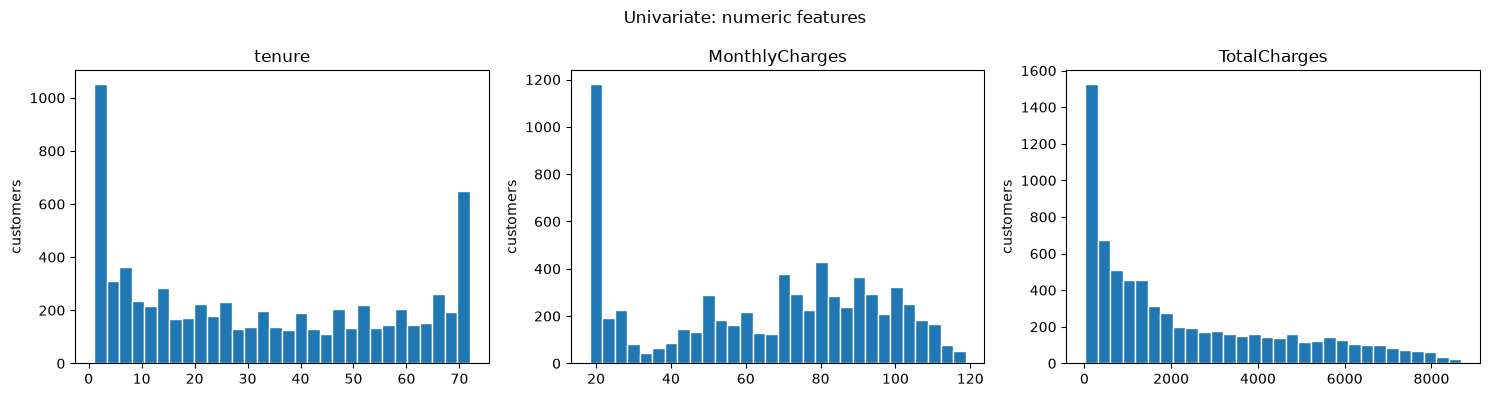

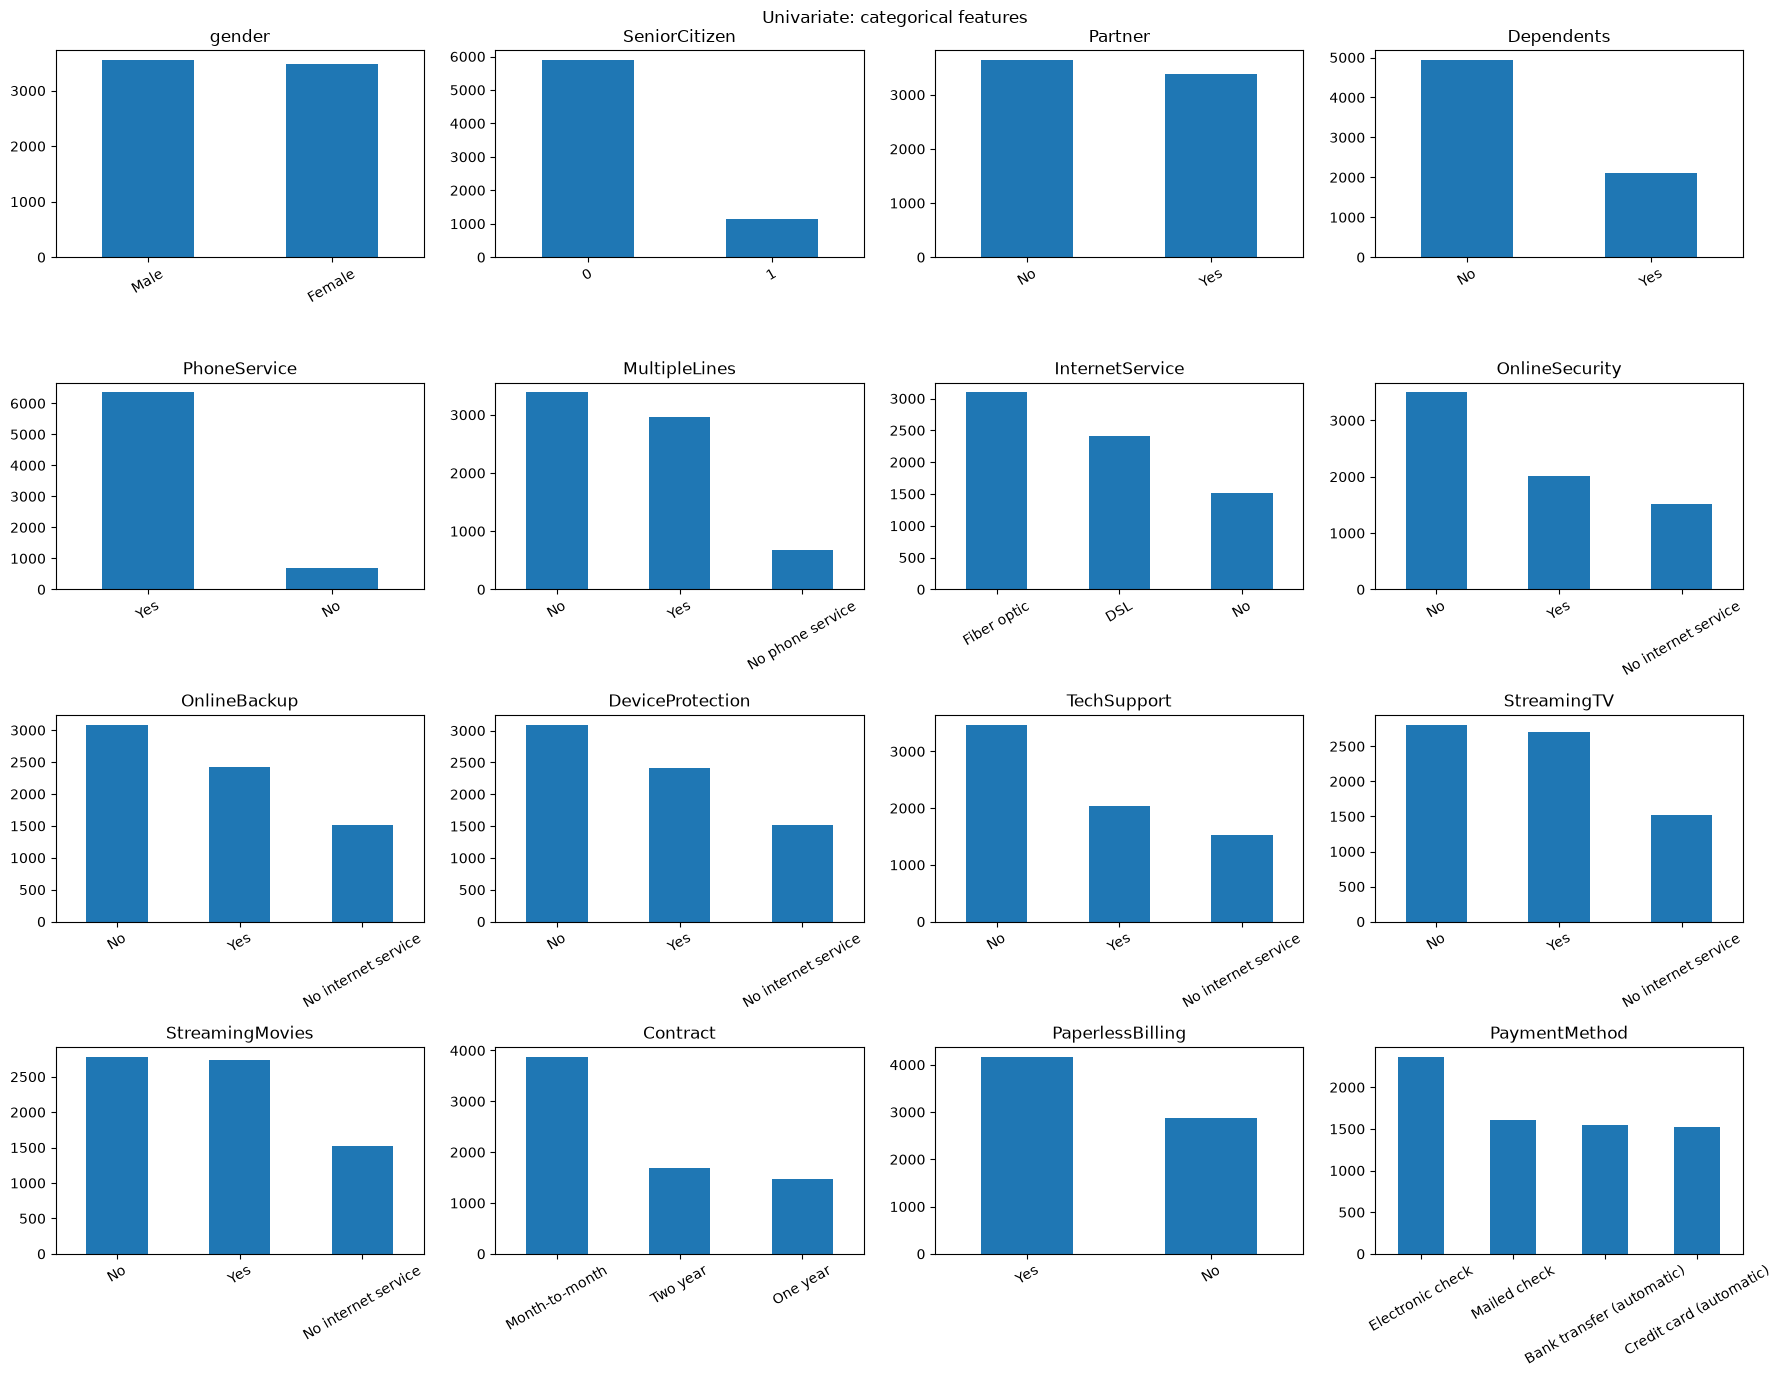

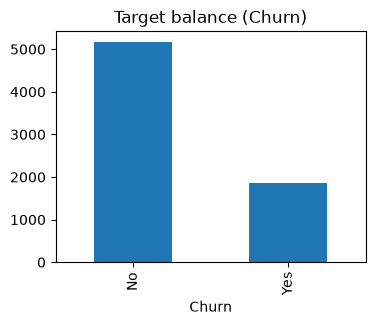

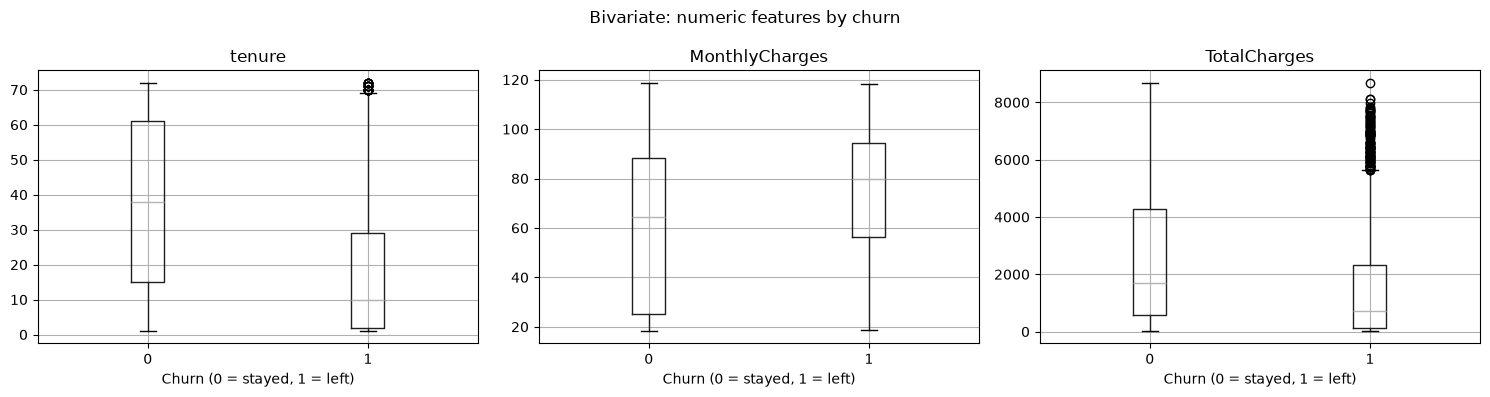

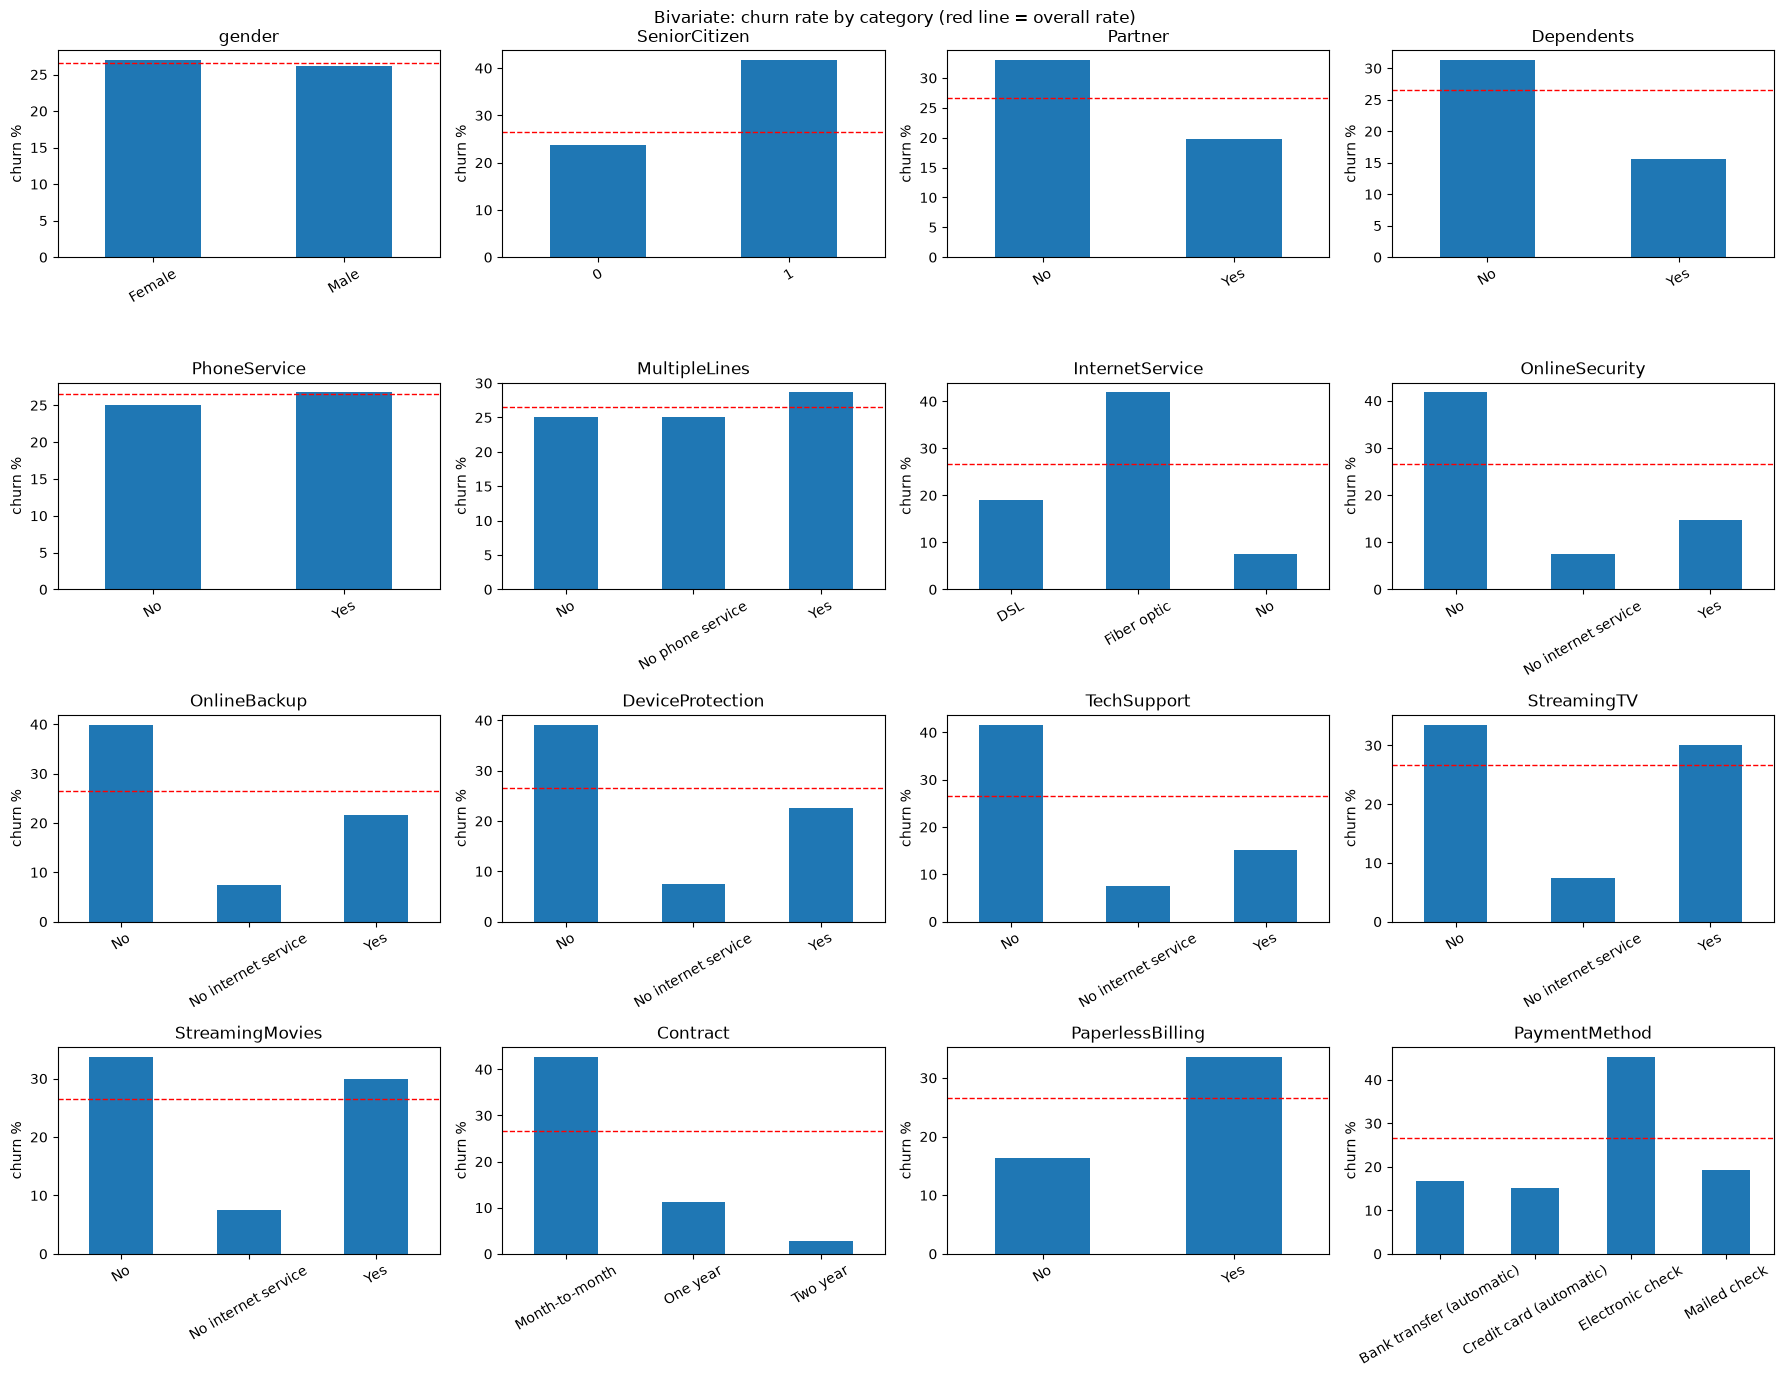

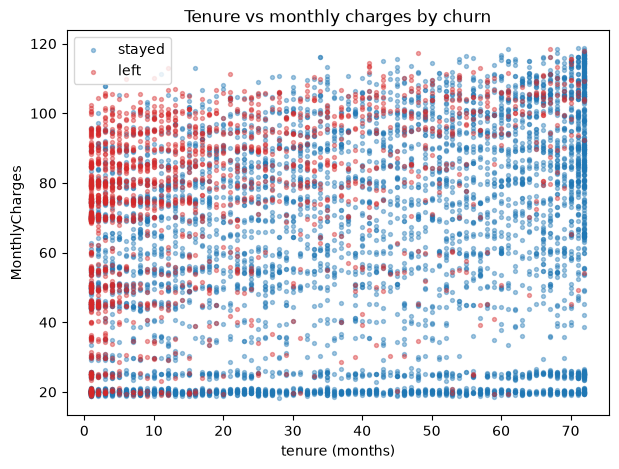

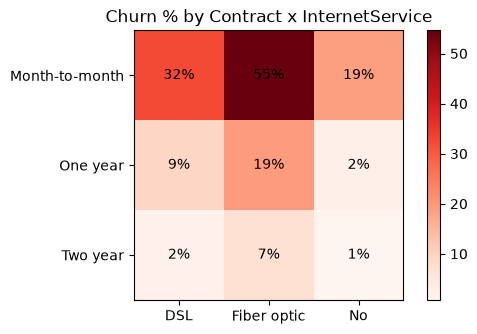

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
tenure,1.00,0.25,0.83,0.02,-0.35
MonthlyCharges,0.25,1.00,0.65,0.22,0.19
TotalCharges,0.83,0.65,1.00,0.10,-0.20
SeniorCitizen,0.02,0.22,0.10,1.00,0.15
Churn,-0.35,0.19,-0.20,0.15,1.00


In [30]:
# ============ UNIVARIATE ============
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df_2.columns if c not in num_cols + ["Churn"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    ax.hist(df_2[col], bins=30, edgecolor="white")
    ax.set_title(col); ax.set_ylabel("customers")
plt.suptitle("Univariate: numeric features"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.ravel(), cat_cols):
    df_2[col].value_counts().plot(kind="bar", ax=ax, title=col)
    ax.tick_params(axis="x", rotation=30); ax.set_xlabel("")
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.suptitle("Univariate: categorical features"); plt.tight_layout(); plt.show()

df_2["Churn"].map({0: "No", 1: "Yes"}).value_counts().plot(
    kind="bar", title="Target balance (Churn)", figsize=(4, 3))
plt.show()


# ============ BIVARIATE (each feature vs churn) ============
# numeric vs churn
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    df_2.boxplot(column=col, by="Churn", ax=ax)
    ax.set_title(col); ax.set_xlabel("Churn (0 = stayed, 1 = left)")
plt.suptitle("Bivariate: numeric features by churn"); plt.tight_layout(); plt.show()

# categorical vs churn: churn RATE per category
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.ravel(), cat_cols):
    (df_2.groupby(col)["Churn"].mean() * 100).plot(kind="bar", ax=ax, title=col)
    ax.axhline(df_2["Churn"].mean() * 100, color="red", ls="--", lw=1)  # overall rate
    ax.set_ylabel("churn %"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.suptitle("Bivariate: churn rate by category (red line = overall rate)")
plt.tight_layout(); plt.show()


# ============ MULTIVARIATE (several features together) ============
# 1) tenure x monthly charges, coloured by churn
fig, ax = plt.subplots(figsize=(7, 5))
for label, colour in [(0, "tab:blue"), (1, "tab:red")]:
    s = df_2[df_2["Churn"] == label]
    ax.scatter(s["tenure"], s["MonthlyCharges"], s=8, alpha=0.4, c=colour,
               label="left" if label else "stayed")
ax.set_xlabel("tenure (months)"); ax.set_ylabel("MonthlyCharges"); ax.legend()
ax.set_title("Tenure vs monthly charges by churn"); plt.show()

# 2) churn rate by contract x internet service
pivot = df_2.pivot_table(values="Churn", index="Contract",
                         columns="InternetService", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(6, 3.5))
im = ax.imshow(pivot, cmap="Reds")
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.iloc[i, j]:.0f}%", ha="center", va="center")
ax.set_title("Churn % by Contract x InternetService"); plt.colorbar(im); plt.show()

# 3) correlation of numeric features with churn
df_2[num_cols + ["SeniorCitizen", "Churn"]].corr().round(2)

In [31]:
df_2.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [32]:
df.Churn.head()

0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: str

In [33]:
df_2.Churn.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [34]:
df_3 = pd.get_dummies(df_2)
df_3.head(3)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,True,False,False,True,True,...,False,True,False,False,False,True,False,False,True,False
1,0,34,56.95,1889.50,0,False,True,True,False,True,...,False,False,True,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,False,True,True,False,True,...,False,True,False,False,False,True,False,False,False,True


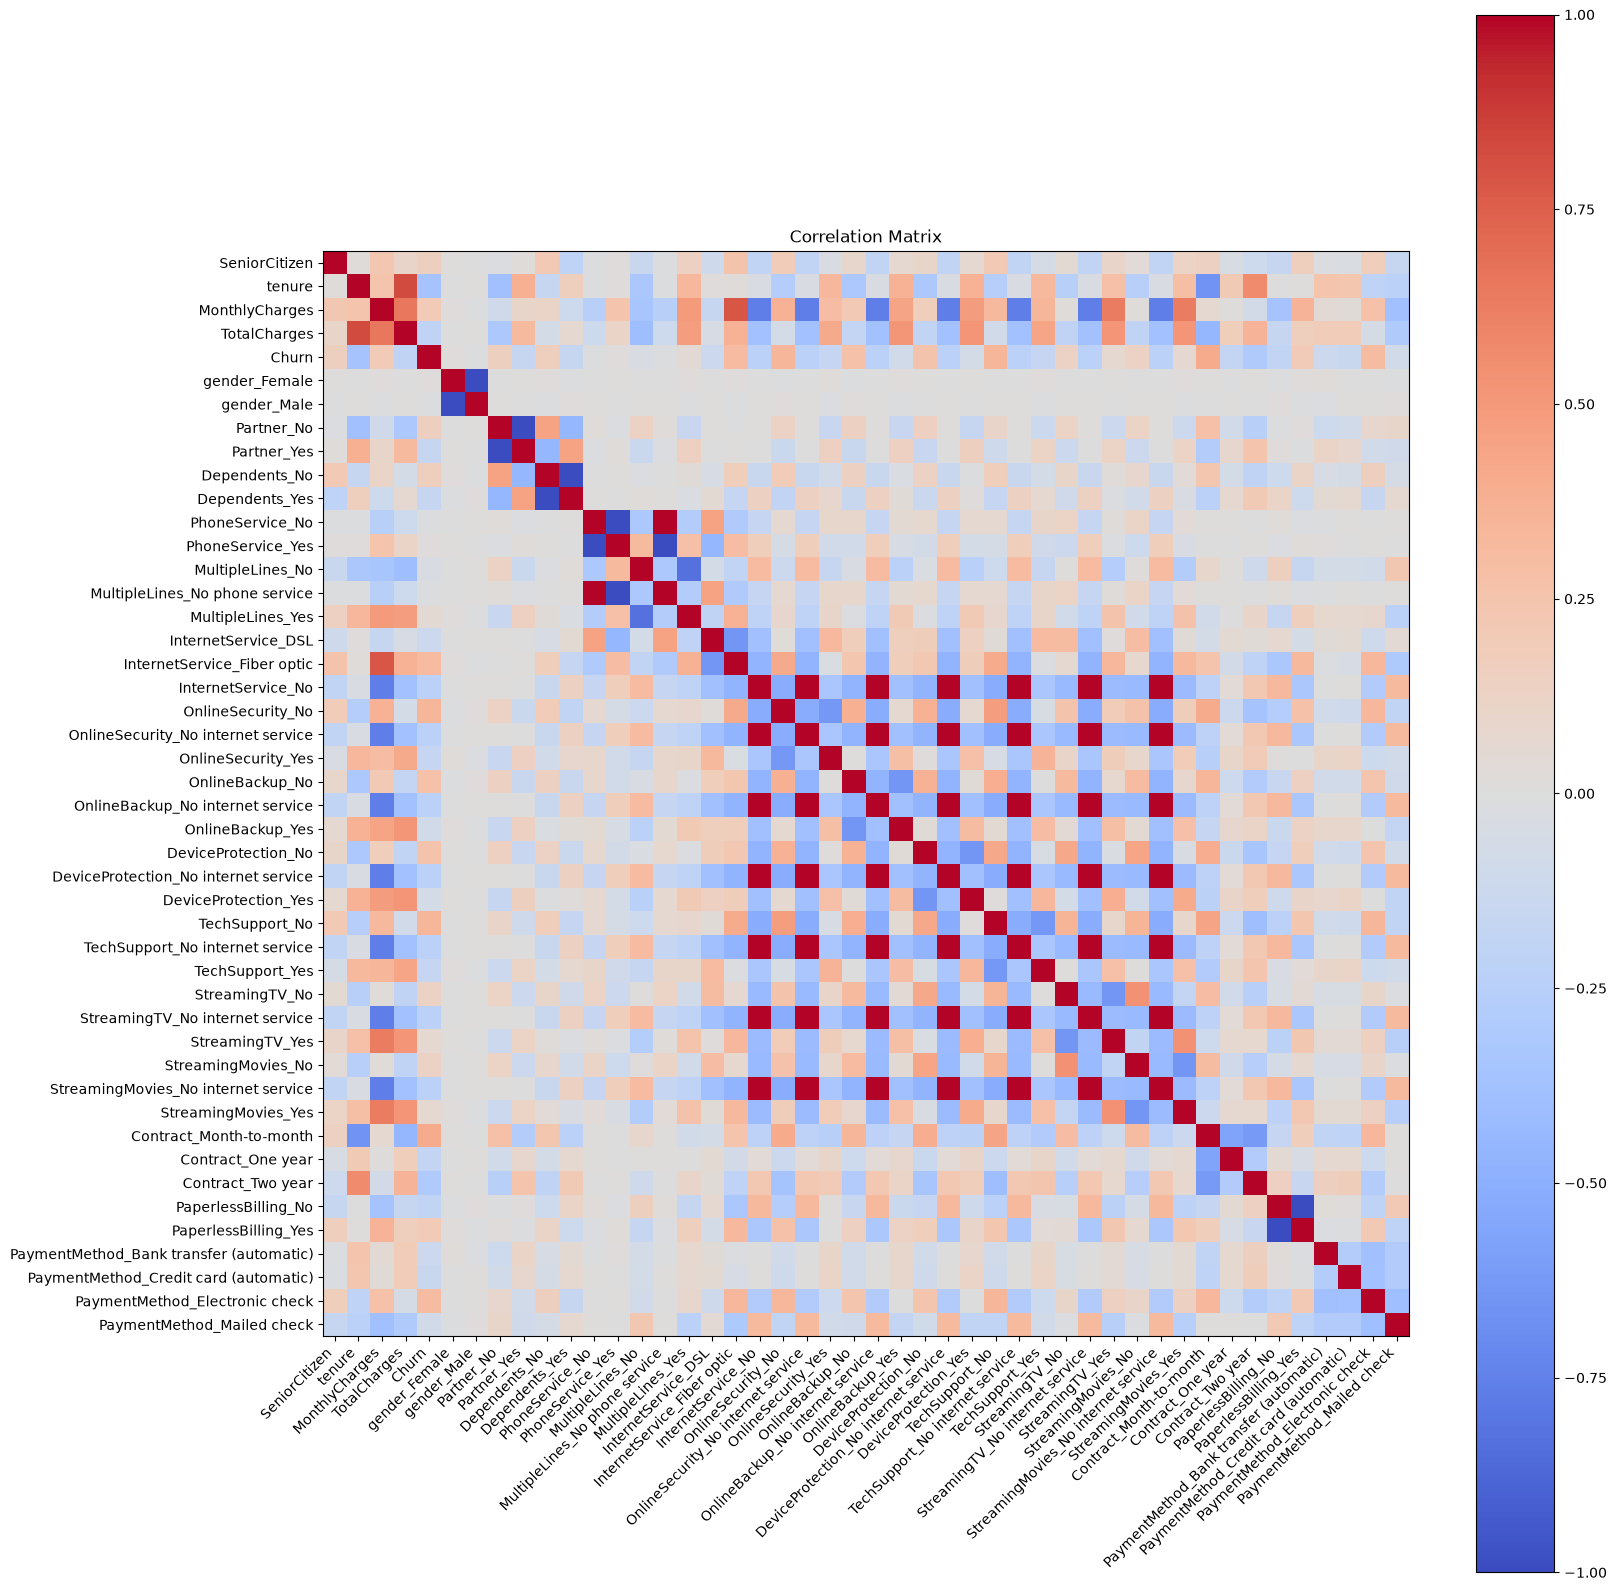

In [35]:
# # 1. Calculate the correlation matrix
corr_matrix = df_3.corr()

# 2. Plot using Matplotlib
fig, ax = plt.subplots(figsize=(17, 17))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)

# Add colorbar and labels
fig.colorbar(im, ax=ax)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha='right')
ax.set_yticklabels(corr_matrix.columns)
ax.set_title('Correlation Matrix')

plt.tight_layout()
plt.show()

In [36]:
df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1)


,tenure,MonthlyCharges
Churn,,
No,37.6,61.3
Yes,18.0,74.4



## Modeling

Random Forest

Logistic Regression

Decision Tree (BASE MODEL)

XG Boost

ANN ( number of hidden layers, epochs, early stopping)

Saving the model

In [37]:

df_3.dtypes

SeniorCitizen                                int64
tenure                                       int64
MonthlyCharges                             float64
TotalCharges                               float64
Churn                                        int64
gender_Female                                 bool
gender_Male                                   bool
Partner_No                                    bool
Partner_Yes                                   bool
Dependents_No                                 bool
Dependents_Yes                                bool
PhoneService_No                               bool
PhoneService_Yes                              bool
MultipleLines_No                              bool
MultipleLines_No phone service                bool
MultipleLines_Yes                             bool
InternetService_DSL                           bool
InternetService_Fiber optic                   bool
InternetService_No                            bool
OnlineSecurity_No              

In [38]:
df_3.isna().sum()/len(df_3)

SeniorCitizen                              0.0
tenure                                     0.0
MonthlyCharges                             0.0
TotalCharges                               0.0
Churn                                      0.0
gender_Female                              0.0
gender_Male                                0.0
Partner_No                                 0.0
Partner_Yes                                0.0
Dependents_No                              0.0
Dependents_Yes                             0.0
PhoneService_No                            0.0
PhoneService_Yes                           0.0
MultipleLines_No                           0.0
MultipleLines_No phone service             0.0
MultipleLines_Yes                          0.0
InternetService_DSL                        0.0
InternetService_Fiber optic                0.0
InternetService_No                         0.0
OnlineSecurity_No                          0.0
OnlineSecurity_No internet service         0.0
OnlineSecurit

In [39]:
X = df_3.drop(columns=["Churn"])
y = df_3.Churn

In [40]:
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,True,False,False,True,True,False,...,False,True,False,False,False,True,False,False,True,False
1,0,34,56.95,1889.50,False,True,True,False,True,False,...,False,False,True,False,True,False,False,False,False,True
2,0,2,53.85,108.15,False,True,True,False,True,False,...,False,True,False,False,False,True,False,False,False,True
3,0,45,42.30,1840.75,False,True,True,False,True,False,...,False,False,True,False,True,False,True,False,False,False
4,0,2,70.70,151.65,True,False,True,False,True,False,...,False,True,False,False,False,True,False,False,True,False


In [41]:
y.head(2)

0    0
1    0
Name: Churn, dtype: int64

In [42]:

X.shape

(7032, 45)

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3, 
    random_state=42, 
    stratify= y # it will retain a constant proportion when splitting the two classes
)

instantialte the models

In [44]:
classical_models = {
    "DecisionTreeClassifier":DecisionTreeClassifier(max_depth= 20, min_samples_leaf=10,  criterion='entropy', random_state = SEED_VALUE,),
    "logistic_regression": LogisticRegression(max_iter=10000), 
    "random_forest": RandomForestClassifier(n_estimators=1000, min_samples_leaf=10, random_state= SEED_VALUE), 
    "xgboost": XGBClassifier(
        n_estimators = 3000, max_depth = 20, learning_rate=0.01, eval_metric="logloss", random_state =SEED_VALUE 
    )
}

In [45]:
# get classical model 
# train the model 
# save the model 

for name, model in classical_models.items(): 
    #  get model&   train model
    model.fit(X_train, y_train)
    #  save model
    joblib.dump(model, f"{name}_model.joblib")
    
    #  predict value

Evaluation

In [46]:
# evaluation function ( accuracy, precision., recall, f1-score, roc_auc)
def evaluationCalculator(y_test, proba, threshold = 0.5 ):
    pred = (proba>threshold).astype(int)
    return {
        "accuracy": f"{accuracy_score(y_test, pred):.2f}", 
        "precision":f"{precision_score(y_test, pred):.2f}",
        "recall":f"{recall_score(y_test, pred):.2f}",
        "f1-score":f"{f1_score(y_test, pred):.2f}",
        "roc_auc-score":f"{roc_auc_score(y_test, pred):.2f}"
    }

In [47]:
probability_values = {}
model_outcome_evals = []

for name, model in classical_models.items(): 
    #  get model&   train model
    model.fit(X_train, y_train) 
    #  get the prob values
    probability_values[name] = lambda X, m = model: model.predict_proba(X)[:,1]
    evaluation = evaluationCalculator(y_test=y_test,proba=probability_values[name](X_test))

    model_outcome_evals.append(
        {
            "model": name, 
            "evaluation": evaluation
        }
    )

    #  evaluate the model
    print("="*40, f"{name}", "="*40) 
    print(evaluation)
    print("="*100) 
    #  print score

======================================== DecisionTreeClassifier ========================================
{'accuracy': '0.77', 'precision': '0.58', 'recall': '0.50', 'f1-score': '0.54', 'roc_auc-score': '0.68'}
======================================== logistic_regression ========================================
{'accuracy': '0.81', 'precision': '0.66', 'recall': '0.57', 'f1-score': '0.61', 'roc_auc-score': '0.73'}


======================================== random_forest ========================================
{'accuracy': '0.79', 'precision': '0.64', 'recall': '0.48', 'f1-score': '0.55', 'roc_auc-score': '0.69'}
======================================== xgboost ========================================
{'accuracy': '0.77', 'precision': '0.59', 'recall': '0.51', 'f1-score': '0.54', 'roc_auc-score': '0.69'}


In [48]:
probability_values = {}

for name, model in classical_models.items(): 
    #  get model&   train model
    model.fit(X_train, y_train) 
    #  get the prob values
    probability_values[name] = lambda X, m = model: model.predict_proba(X)[:,1]

    #  evaluate the model
    print("="*40, f"{name}", "="*40) 
    print(evaluationCalculator(y_test=y_test,proba=probability_values[name](X_test)))
    print("="*100) 
    #  print score

======================================== DecisionTreeClassifier ========================================
{'accuracy': '0.77', 'precision': '0.58', 'recall': '0.50', 'f1-score': '0.54', 'roc_auc-score': '0.68'}
======================================== logistic_regression ========================================
{'accuracy': '0.81', 'precision': '0.66', 'recall': '0.57', 'f1-score': '0.61', 'roc_auc-score': '0.73'}
======================================== random_forest ========================================
{'accuracy': '0.79', 'precision': '0.64', 'recall': '0.48', 'f1-score': '0.55', 'roc_auc-score': '0.69'}
======================================== xgboost ========================================
{'accuracy': '0.77', 'precision': '0.59', 'recall': '0.51', 'f1-score': '0.54', 'roc_auc-score': '0.69'}


In [49]:
probability_values

{'DecisionTreeClassifier': <function __main__.<lambda>(X, m=DecisionTreeClassifier(criterion='entropy', max_depth=20, min_samples_leaf=10,
                       random_state=42))>,
 'logistic_regression': <function __main__.<lambda>(X, m=LogisticRegression(max_iter=10000))>,
 'random_forest': <function __main__.<lambda>(X, m=RandomForestClassifier(min_samples_leaf=10, n_estimators=1000, random_state=42))>,
 'xgboost': <function __main__.<lambda>(X, m=XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.01, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_de

In [50]:
# Neural Net  - has 3 hidden layers with 1st layer having 64 neurons, 2nd - 32 neuron, 3rd 16 neurons


#  model definiton
dnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1], )),          # one customer = n_features numbers

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3), 

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3), 

    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.3), 

    tf.keras.layers.Dense(1, activation="sigmoid") # OUTPUT: 1 neuron, a probability between 0 and 1
])

dnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,257 (63.50 KB)

 Trainable params: 16,257 (63.50 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
#  compilation
dnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="roc_auc")]
)

In [52]:
#e arly stopping
early_stop = tf.keras.callbacks.EarlyStopping( monitor="val_loss", patience=10, restore_best_weights=True)

#  run predictions
history = dnn_model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=200,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.6536 - loss: 23.2584 - roc_auc: 0.5673 - val_accuracy: 0.7700 - val_loss: 2.6397 - val_roc_auc: 0.6197
Epoch 2/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6648 - loss: 4.7809 - roc_auc: 0.5841 - val_accuracy: 0.7524 - val_loss: 0.6088 - val_roc_auc: 0.6238
Epoch 3/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6581 - loss: 2.0098 - roc_auc: 0.5957 - val_accuracy: 0.7375 - val_loss: 0.6474 - val_roc_auc: 0.6168
Epoch 4/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7093 - loss: 1.1858 - roc_auc: 0.6052 - val_accuracy: 0.7375 - val_loss: 0.6331 - val_roc_auc: 0.6102
Epoch 5/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7244 - loss: 0.8182 - roc_auc: 0.6136 - val_accuracy: 0.7375 - val_loss: 0.6106 - val_roc_auc: 0.6154
Epoch 6/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7354 - loss: 0.7843 - roc_auc: 0.6190 - val_accuracy: 0.7375 - val_loss: 0.5884 - val_

In [53]:
#  saves the model
dnn_model.save("dnn.keras")

In [54]:
#  get model&   train model
dnn_model.fit(X_train, y_train) 
    #  get the prob values
probability_values["deep_neural_net"] = lambda X : dnn_model.predict(X, verbose=1).ravel()
dnn_evaluation = evaluationCalculator(y_test=y_test,proba=probability_values["deep_neural_net"](X_test))

model_outcome_evals.append( 

    {"model":"deep_neural_net", 
    "evaluation":dnn_evaluation}
)
    #  evaluate the model
print("="*40,  "deep_neural_net", "="*40) 
print(dnn_evaluation)
print("="*100) 

154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7950 - loss: 0.4492 - roc_auc: 0.8169
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
======================================== deep_neural_net ========================================
{'accuracy': '0.79', 'precision': '0.66', 'recall': '0.42', 'f1-score': '0.52', 'roc_auc-score': '0.67'}


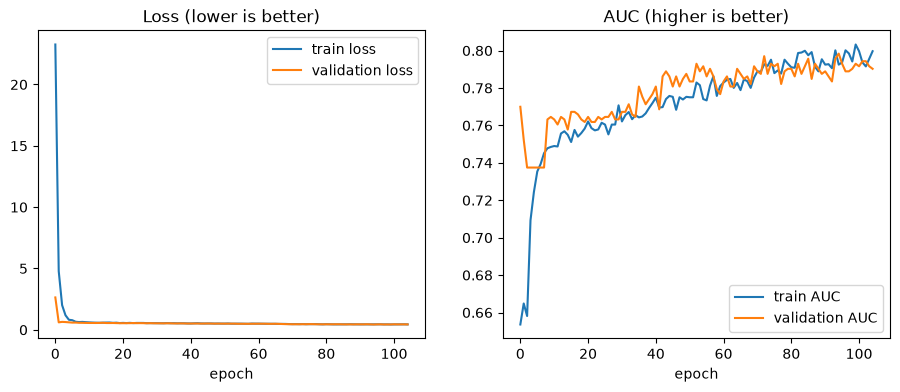

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history.history["loss"], label="train loss")
ax[0].plot(history.history["val_loss"], label="validation loss")
ax[0].set_title("Loss (lower is better)"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(history.history["accuracy"], label="train AUC")
ax[1].plot(history.history["val_accuracy"], label="validation AUC")
ax[1].set_title("AUC (higher is better)"); ax[1].set_xlabel("epoch"); ax[1].legend()

plt.show()

In [56]:
for model_outcome in model_outcome_evals:
    print(f"{model_outcome['model']} \n{model_outcome['evaluation']}\n")
    print("-"*100)

DecisionTreeClassifier 
{'accuracy': '0.77', 'precision': '0.58', 'recall': '0.50', 'f1-score': '0.54', 'roc_auc-score': '0.68'}

----------------------------------------------------------------------------------------------------
logistic_regression 
{'accuracy': '0.81', 'precision': '0.66', 'recall': '0.57', 'f1-score': '0.61', 'roc_auc-score': '0.73'}

----------------------------------------------------------------------------------------------------
random_forest 
{'accuracy': '0.79', 'precision': '0.64', 'recall': '0.48', 'f1-score': '0.55', 'roc_auc-score': '0.69'}

----------------------------------------------------------------------------------------------------
xgboost 
{'accuracy': '0.77', 'precision': '0.59', 'recall': '0.51', 'f1-score': '0.54', 'roc_auc-score': '0.69'}

----------------------------------------------------------------------------------------------------
deep_neural_net 
{'accuracy': '0.79', 'precision': '0.66', 'recall': '0.42', 'f1-score': '0.52', 'roc_a

### Hyper parameter tuning

In [57]:
# ============ put under "Hyper parameter tuning" ============
# (needs the cells above: X_train, X_test, y_train, y_test, SEED_VALUE)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, recall_score, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED_VALUE)
spw = (y_train == 0).sum() / (y_train == 1).sum()      # imbalance ratio for XGBoost

search_space = {
    "decision_tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=SEED_VALUE),
        {"max_depth": [3, 4, 5, 6, 8], "min_samples_leaf": [5, 10, 20, 40],
         "criterion": ["gini", "entropy"]}),
    "logistic_regression": (
        LogisticRegression(max_iter=10000, class_weight="balanced"),
        {"C": [0.01, 0.1, 1, 10, 100]}),
    "random_forest": (
        RandomForestClassifier(class_weight="balanced", random_state=SEED_VALUE, n_jobs=-1),
        {"n_estimators": [200, 400], "max_depth": [4, 6, 8, None],
         "min_samples_leaf": [5, 10, 20]}),
    "xgboost": (
        XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=SEED_VALUE),
        {"n_estimators": [200, 400], "max_depth": [2, 3, 4, 5],
         "learning_rate": [0.01, 0.05, 0.1], "subsample": [0.8, 1.0]}),
}

tuned_models, rows = {}, []
for name, (estimator, grid) in search_space.items():
    search = RandomizedSearchCV(estimator, grid, n_iter=8, scoring="roc_auc",
                                cv=cv, random_state=SEED_VALUE, n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    tuned_models[name] = best
    proba = best.predict_proba(X_test)[:, 1]
    rows.append({"model": name, "cv_auc": round(search.best_score_, 3),
                 "test_auc": round(roc_auc_score(y_test, proba), 3),
                 "recall": round(recall_score(y_test, proba >= 0.5), 3),
                 "f1": round(f1_score(y_test, proba >= 0.5), 3),
                 "best_params": search.best_params_})

tuning_results = pd.DataFrame(rows).sort_values("test_auc", ascending=False)
tuning_results




c:\Users\user\Desktop\DataToolDeployment101\env\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 5 is smaller than n_iter=8. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


,model,cv_auc,test_auc,recall,f1,best_params
3,xgboost,0.848,0.839,0.793,0.623,"{'subsample': 0.8, 'n_estimators': 200, 'max_d..."
1,logistic_regression,0.848,0.837,0.793,0.612,{'C': 100}
2,random_forest,0.850,0.837,0.795,0.624,"{'n_estimators': 400, 'min_samples_leaf': 5, '..."
0,decision_tree,0.833,0.826,0.774,0.609,"{'min_samples_leaf': 40, 'max_depth': 4, 'crit..."


https://www.geeksforgeeks.org/machine-learning/hyperparameter-tuning/

## Deployment

PowerBI

FastAPI

Streamlit

(XAI)

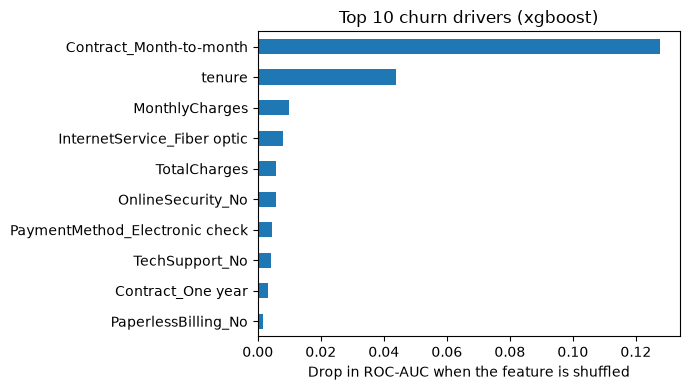

In [ ]:
from sklearn.inspection import permutation_importance

best_name = tuning_results.iloc[0]["model"]
best_model = tuned_models[best_name]
imp = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                             n_repeats=5, random_state=SEED_VALUE, n_jobs=-1)
importance = (pd.Series(imp.importances_mean, index=X_test.columns)
              .sort_values(ascending=False).head(10))

importance[::-1].plot(kind="barh", figsize=(7, 4),
                      title=f"Top 10 churn drivers ({best_name})")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.tight_layout(); plt.show()

In [61]:
joblib.load("models/logistic_regression.joblib")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'

In [64]:
joblib.load("models/decision_tree.joblib")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'